# Portuguese Bank Marketing – Capstone Project

**Name:** Deenadayalan A S 
**Batch ID:**06-JUL-26-CDS-BUN-021-WDM1130-CHE-ANN
**Domain:** Banking / Finance  
**Dataset:** `bank-additional-full.csv`

## Project objectives
1. Understand and analyse the bank marketing dataset.
2. Build a simple predictive model to estimate whether a customer may subscribe to a term deposit.
3. Evaluate the predictions.
4. Give suggestions to the bank marketing team.

**Important:** This version avoids Scikit-learn. It uses Pandas and NumPy for data preparation, implements Logistic Regression with NumPy, and includes hand-built Gini-based Decision Tree and Random Forest models using Python and NumPy. Extra Trees is not included. `duration` is excluded because it is known only after the phone call.

Run the notebook from top to bottom, one cell at a time.

## 1. Import libraries
I used Pandas and NumPy for data processing, and Matplotlib and Seaborn for visualisation.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset
I have used the path of the dataset in pc for this notebook. The dataset uses semicolons (`;`) between columns.
Please make that the data path matches or change it according to the dataset's path in your PC

In [27]:
df = pd.read_csv("C:\\Users\\asdee\\OneDrive\\Documents\\Portuguese_Bank_ML_Project\\bank-additional-full.csv", sep=";")

print("Dataset loaded successfully.")
print("Rows and columns:", df.shape)
df

Dataset loaded successfully.
Rows and columns: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


## 3. Understand the dataset

In [28]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [30]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [31]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Column names:")
print(df.columns.tolist())

Rows: 41188
Columns: 21
Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


## 4. Check and clean the data
Checking the missing values, exact duplicate rows and target values. The value `unknown` is a category in the source data, not a blank value.

In [32]:
print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())
print("\nTarget counts:")
display(df["y"].value_counts())

Missing values:


age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Duplicate rows: 12

Target counts:


y
no     36548
yes     4640
Name: count, dtype: int64

In [33]:
df = df.drop_duplicates().copy()
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (41176, 21)


## 5. Exploratory Data Analysis (EDA)

### 5.1 Target distribution

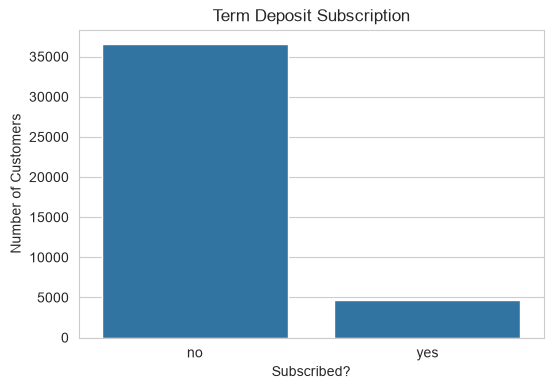

Subscription rate: 11.27%


In [34]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y")
plt.title("Term Deposit Subscription")
plt.xlabel("Subscribed?")
plt.ylabel("Number of Customers")
plt.show()

subscription_rate = (df["y"] == "yes").mean() * 100
print("Subscription rate: {:.2f}%".format(subscription_rate))

### 5.2 Age distribution

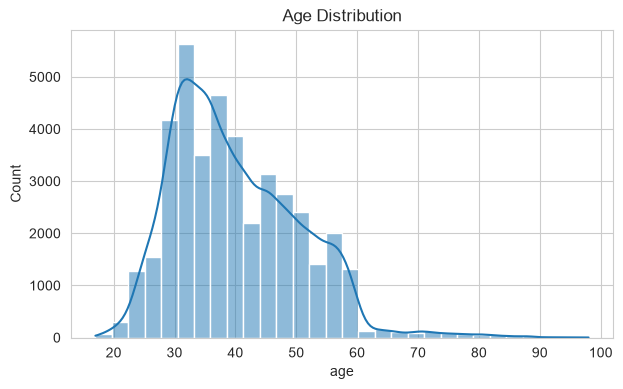

In [35]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="age", bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

### 5.3 Customers by job

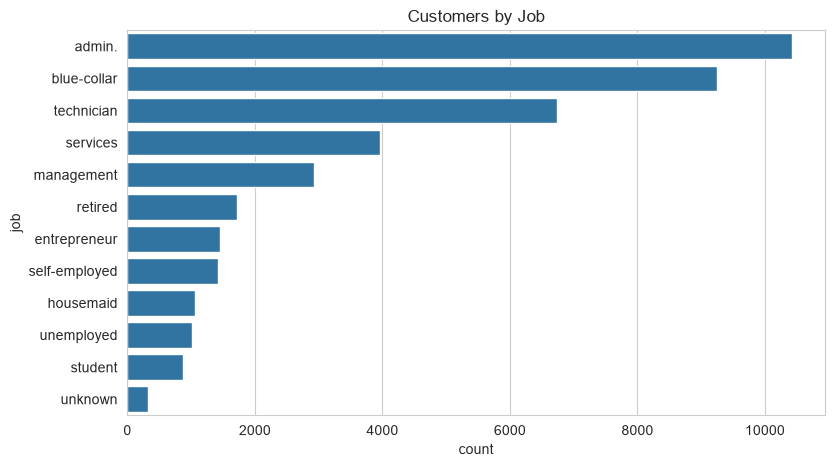

In [36]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, y="job", order=df["job"].value_counts().index)
plt.title("Customers by Job")
plt.show()

### 5.4 Subscription rate by contact type

,Subscription rate (%)
contact,
cellular,14.738856
telephone,5.232365


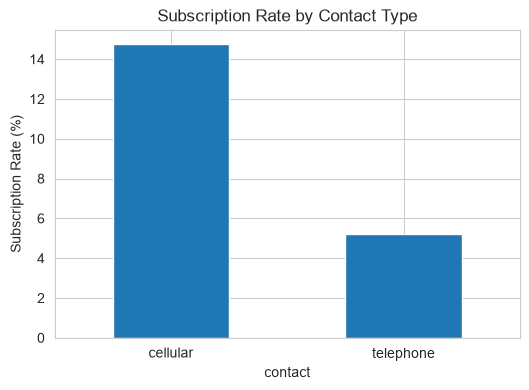

In [37]:
contact_rate = df.groupby("contact")["y"].apply(lambda s: (s == "yes").mean() * 100)
display(contact_rate.to_frame("Subscription rate (%)"))

contact_rate.plot(kind="bar", figsize=(6, 4))
plt.title("Subscription Rate by Contact Type")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.show()

### 5.5 Subscription rate by education

,Subscription rate (%)
education,
basic.4y,10.249042
basic.6y,8.206024
basic.9y,7.824648
high.school,10.838940
illiterate,22.222222
professional.course,11.354962
university.degree,13.720816
unknown,14.508671


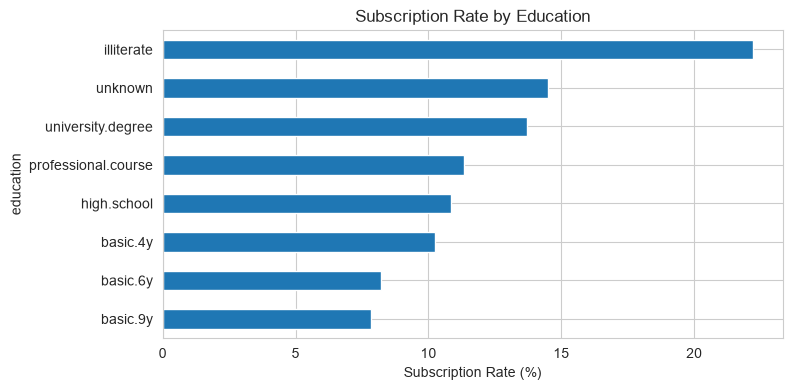

In [38]:
education_rate = df.groupby("education")["y"].apply(lambda s: (s == "yes").mean() * 100)
display(education_rate.to_frame("Subscription rate (%)"))

education_rate.sort_values().plot(kind="barh", figsize=(8, 4))
plt.title("Subscription Rate by Education")
plt.xlabel("Subscription Rate (%)")
plt.show()

### 5.6 Correlation heatmap

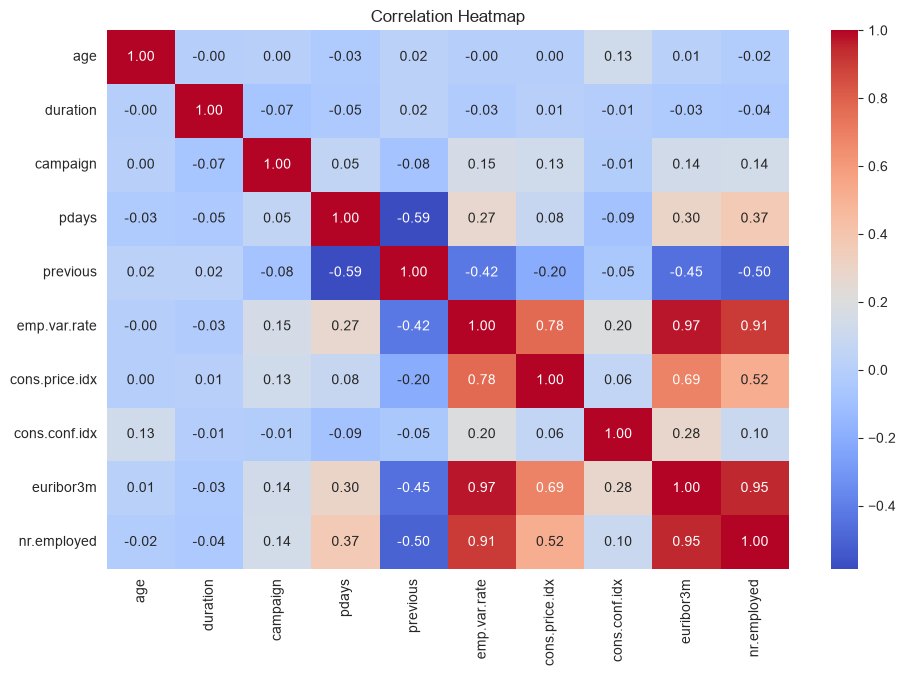

In [39]:
plt.figure(figsize=(11, 7))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## 6. Prepare the data
Convert the target to 0 and 1. Remove `duration` to avoid using information that would not be available before a marketing call.

In [40]:
df["y"] = df["y"].map({"no": 0, "yes": 1})

X = df.drop(["y", "duration"], axis=1)
y = df["y"].to_numpy()

print("Input features:", X.shape)
print("Target values:", np.unique(y))

Input features: (41176, 19)
Target values: [0 1]


## 7. Convert categorical data into numbers
`pd.get_dummies()` performs One-Hot Encoding. Then we make sure every feature is numeric.

In [41]:
X = pd.get_dummies(X, drop_first=True, dtype=int)
X = X.astype(float)

print("Shape after encoding:", X.shape)
display(X.head())

Shape after encoding: (41176, 52)


,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,job_blue-collar,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56.0,1.0,999.0,0.0,1.1,93.994,-36.4,4.857,5191.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,57.0,1.0,999.0,0.0,1.1,93.994,-36.4,4.857,5191.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,37.0,1.0,999.0,0.0,1.1,93.994,-36.4,4.857,5191.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,40.0,1.0,999.0,0.0,1.1,93.994,-36.4,4.857,5191.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,56.0,1.0,999.0,0.0,1.1,93.994,-36.4,4.857,5191.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


## 8. Split training and testing data
We use 80% for training and 20% for testing. NumPy is used to shuffle and split the row indexes.

In [42]:
np.random.seed(42)

indices = np.random.permutation(len(X))
split_point = int(len(X) * 0.80)

train_indices = indices[:split_point]
test_indices = indices[split_point:]

X_train = X.iloc[train_indices].to_numpy()
X_test = X.iloc[test_indices].to_numpy()
y_train = y[train_indices]
y_test = y[test_indices]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 32940
Testing rows: 8236


## 9. Scale numerical values
We scale each column using the training-set mean and standard deviation. The same training values are then applied to the test data.

In [43]:
mean_values = X_train.mean(axis=0)
std_values = X_train.std(axis=0)
std_values[std_values == 0] = 1

X_train_scaled = (X_train - mean_values) / std_values
X_test_scaled = (X_test - mean_values) / std_values

print("Feature scaling completed.")

Feature scaling completed.


## 10. Build Logistic Regression using NumPy
This section implements a basic Logistic Regression model without Scikit-learn.

- The sigmoid function converts model output into a value between 0 and 1.
- Gradient descent updates the model weights to reduce prediction error.
- A threshold of 0.5 is used to classify a customer as `yes` or `no`.

This is a simple educational implementation, not a replacement for a thoroughly validated production modelling pipeline.

In [44]:
# Add a column of 1s for the intercept (bias)
X_train_bias = np.c_[np.ones(X_train_scaled.shape[0]), X_train_scaled]
X_test_bias = np.c_[np.ones(X_test_scaled.shape[0]), X_test_scaled]

# Initialise model weights
weights = np.zeros(X_train_bias.shape[1])

def sigmoid(z):
    # Clip values to avoid numerical overflow
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# Train using gradient descent
learning_rate = 0.01
epochs = 1000
number_of_rows = len(y_train)

for epoch in range(epochs):
    predictions = sigmoid(X_train_bias @ weights)
    errors = predictions - y_train
    gradients = (X_train_bias.T @ errors) / number_of_rows
    weights = weights - learning_rate * gradients

print("Logistic Regression training completed.")

Logistic Regression training completed.


## 11. Make predictions

In [45]:
# Calculate subscription probabilities for test customers
test_probabilities = sigmoid(X_test_bias @ weights)

# Convert probabilities into yes (1) or no (0)
test_predictions = (test_probabilities >= 0.5).astype(int)

print("First 10 actual values:     ", y_test[:10])
print("First 10 predicted values:  ", test_predictions[:10])

First 10 actual values:      [1 0 0 0 0 0 0 0 0 0]
First 10 predicted values:   [0 0 0 0 0 0 0 0 0 0]


## 12. Evaluate the model
We calculate accuracy, precision, recall and F1-score using simple Python functions, without Scikit-learn.

In [46]:
true_positive = np.sum((y_test == 1) & (test_predictions == 1))
true_negative = np.sum((y_test == 0) & (test_predictions == 0))
false_positive = np.sum((y_test == 0) & (test_predictions == 1))
false_negative = np.sum((y_test == 1) & (test_predictions == 0))

accuracy = (true_positive + true_negative) / len(y_test)
precision = true_positive / (true_positive + false_positive) if (true_positive + false_positive) else 0
recall = true_positive / (true_positive + false_negative) if (true_positive + false_negative) else 0
f1_score = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0

evaluation = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [accuracy, precision, recall, f1_score]
})
display(evaluation.round(4))

,Metric,Score
0,Accuracy,0.8964
1,Precision,0.5989
2,Recall,0.2297
3,F1-score,0.3320


### 12.2 Compare models

Compare NumPy logistic regression with a Decision Tree and Random Forest implemented in Python/NumPy, plus a majority-class baseline. The learned models use the same held-out test rows.

In [47]:
def classification_metrics(actual, predicted):
    tp = np.sum((actual == 1) & (predicted == 1))
    fp = np.sum((actual == 0) & (predicted == 1))
    fn = np.sum((actual == 1) & (predicted == 0))
    tn = np.sum((actual == 0) & (predicted == 0))
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {"Accuracy": (tp + tn) / len(actual), "Precision": precision, "Recall": recall, "F1-score": f1}

def best_gini_split(X_data, y_data, row_ids, feature_ids, max_thresholds=12):
    """Find a binary split by minimizing weighted Gini impurity."""
    n_rows = len(row_ids)
    if n_rows < 2:
        return None
    parent_positive = np.sum(y_data[row_ids] == 1)
    parent_negative = n_rows - parent_positive
    parent_impurity = 1.0 - (parent_positive / n_rows) ** 2 - (parent_negative / n_rows) ** 2
    best = None
    best_cost = parent_impurity * n_rows
    for feature_id in feature_ids:
        values = X_data[row_ids, feature_id]
        order = np.argsort(values, kind="mergesort")
        sorted_values = values[order]
        sorted_labels = y_data[row_ids[order]]
        positive_prefix = np.cumsum(sorted_labels == 1)
        candidate_cuts = np.unique(np.linspace(1, n_rows - 1, num=min(max_thresholds, n_rows - 1), dtype=int))
        candidate_cuts = candidate_cuts[sorted_values[candidate_cuts - 1] < sorted_values[candidate_cuts]]
        for cut in candidate_cuts:
            left_n = int(cut)
            right_n = n_rows - left_n
            left_pos = int(positive_prefix[cut - 1])
            right_pos = int(parent_positive - left_pos)
            left_neg = left_n - left_pos
            right_neg = right_n - right_pos
            cost = left_n - (left_pos ** 2 + left_neg ** 2) / left_n
            cost += right_n - (right_pos ** 2 + right_neg ** 2) / right_n
            if cost < best_cost:
                threshold = sorted_values[cut - 1] + (sorted_values[cut] - sorted_values[cut - 1]) / 2
                best_cost = cost
                best = (int(feature_id), threshold)
    return best

def fit_decision_tree(X_data, y_data, max_depth=6, min_samples_leaf=20, max_features=None, max_thresholds=12, rng=None):
    """Train a small binary CART-style tree using Gini impurity."""
    all_features = np.arange(X_data.shape[1])
    def grow(row_ids, depth):
        positives = int(np.sum(y_data[row_ids] == 1))
        prediction = int(positives >= len(row_ids) / 2)
        if depth >= max_depth or positives == 0 or positives == len(row_ids) or len(row_ids) < 2 * min_samples_leaf:
            return {"prediction": prediction}
        features = all_features
        if max_features is not None and max_features < len(all_features):
            features = rng.choice(all_features, size=max_features, replace=False)
        split = best_gini_split(X_data, y_data, row_ids, features, max_thresholds)
        if split is None:
            return {"prediction": prediction}
        feature_id, threshold = split
        left_ids = row_ids[X_data[row_ids, feature_id] <= threshold]
        right_ids = row_ids[X_data[row_ids, feature_id] > threshold]
        if len(left_ids) < min_samples_leaf or len(right_ids) < min_samples_leaf:
            return {"prediction": prediction}
        return {"feature": feature_id, "threshold": threshold,
                "left": grow(left_ids, depth + 1), "right": grow(right_ids, depth + 1),
                "prediction": prediction}
    return grow(np.arange(len(y_data)), 0)

def predict_tree(tree, X_data):
    predictions = np.empty(len(X_data), dtype=int)
    def fill(node, row_ids):
        if len(row_ids) == 0:
            return
        if "feature" not in node:
            predictions[row_ids] = node["prediction"]
            return
        goes_left = X_data[row_ids, node["feature"]] <= node["threshold"]
        fill(node["left"], row_ids[goes_left])
        fill(node["right"], row_ids[~goes_left])
    fill(tree, np.arange(len(X_data)))
    return predictions

# Decision Tree: all features are considered at each split.
decision_tree = fit_decision_tree(
    X_train_scaled, y_train, max_depth=6, min_samples_leaf=20,
    max_features=None, max_thresholds=12
)
dt_predictions = predict_tree(decision_tree, X_test_scaled)

# Random Forest: bootstrap samples and random feature subsets reduce tree correlation.
rng = np.random.default_rng(42)
number_of_trees = 15
features_per_split = max(1, int(np.sqrt(X_train_scaled.shape[1])))
forest = []
for _ in range(number_of_trees):
    bootstrap_ids = rng.integers(0, len(y_train), size=len(y_train))
    tree = fit_decision_tree(
        X_train_scaled[bootstrap_ids], y_train[bootstrap_ids], max_depth=6,
        min_samples_leaf=20, max_features=features_per_split,
        max_thresholds=12, rng=rng
    )
    forest.append(tree)

forest_votes = np.vstack([predict_tree(tree, X_test_scaled) for tree in forest])
rf_predictions = (forest_votes.mean(axis=0) >= 0.5).astype(int)

# Majority-class baseline predicts the most common class in the training data.
majority_class = int(np.mean(y_train) >= 0.5)
baseline_predictions = np.full(y_test.shape, majority_class)
model_predictions = {
    "Logistic Regression (NumPy)": test_predictions,
    "Decision Tree (NumPy)": dt_predictions,
    "Random Forest (NumPy)": rf_predictions,
    "Majority-class baseline": baseline_predictions
}
comparison = pd.DataFrame({name: classification_metrics(y_test, pred) for name, pred in model_predictions.items()}).T
display(comparison.round(4))
print("The Decision Tree and Random Forest use Gini impurity. Review recall, precision, F1 and campaign costs before selecting a candidate; this random holdout alone does not establish production readiness.")

,Accuracy,Precision,Recall,F1-score
Logistic Regression (NumPy),0.8964,0.5989,0.2297,0.332
Decision Tree (NumPy),0.8879,0.0000,0.0000,0.000
Random Forest (NumPy),0.8879,0.0000,0.0000,0.000
Majority-class baseline,0.8879,0.0000,0.0000,0.000


The Decision Tree and Random Forest use Gini impurity. Review recall, precision, F1 and campaign costs before selecting a candidate; this random holdout alone does not establish production readiness.


### 12.3 Logistic Regression confusion matrix

This confusion matrix shows the Logistic Regression predictions.

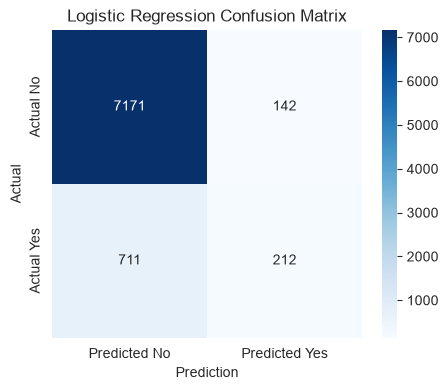

In [48]:
confusion_matrix = np.array([
    [true_negative, false_positive],
    [false_negative, true_positive]
])

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.show()

## 13. Business suggestions
1. Use customer information to help prioritise marketing calls.
2. Review subscription rates by contact type, education, job and other customer groups.
3. Avoid contacting the same customer too frequently.
4. Test different campaign timings and communication methods.
5. Monitor precision and recall to understand unnecessary calls and missed subscribers.
6. Do not use call duration for pre-call predictions because it is only known after the call.

These are suggestions to test with future campaigns; the observed relationships do not prove cause and effect.

## 14. Challenges faced and solutions

In [49]:
challenges = pd.DataFrame({
    "Challenge": [
        "Target class imbalance",
        "Categorical data",
        "Different feature scales",
        "Target leakage",
        "Duplicate rows",
        "Comparing models without Scikit-learn"
    ],
    "Solution": [
        "Report precision, recall and F1-score alongside accuracy; inspect the recall tradeoff.",
        "Use Pandas get_dummies() for one-hot encoding.",
        "Scale features using NumPy training-set means and standard deviations.",
        "Remove duration because it is known only after the call.",
        "Check and remove exact duplicate rows.",
        "Compare NumPy logistic regression, a Gini-based Decision Tree and Random Forest with a majority-class baseline."
    ]
})
display(challenges)

,Challenge,Solution
0,Target class imbalance,"Report precision, recall and F1-score alongsid..."
1,Categorical data,Use Pandas get_dummies() for one-hot encoding.
2,Different feature scales,Scale features using NumPy training-set means ...
3,Target leakage,Remove duration because it is known only after...
4,Duplicate rows,Check and remove exact duplicate rows.
5,Comparing models without Scikit-learn,"Compare NumPy logistic regression, a Gini-base..."


## 15. Conclusion

This project analyses the Portuguese Bank Marketing dataset and compares a NumPy logistic regression model with a Gini-based Decision Tree, a Random Forest, and a majority-class baseline. The Decision Tree and Random Forest are implemented directly with Python and NumPy; the notebook does not use Scikit-learn. The notebook excludes duration because it is unavailable before a call.

Run the notebook from top to bottom to generate the model comparison. Treat the results as an educational comparison rather than a production recommendation: the random holdout is not time-based, and production selection should account for campaign costs, calibration and further validation.